> **Redacted copy for aaronsuu.github.io.** *Dataset not included: it was provided for course use only and contains sensitive responses. Notebook outputs that showed raw data have been removed.* Code and charts are unchanged; the notebook will not run without the data.

# Install Non-Standard Libraries

In [232]:
#Run this cell only once to enable access to functions for expanding contractions and the natural language toolkit
!pip install contractions
!pip install nltk

# Import Modules, Functions, and other Code
Note that the following imports are repeated in cells where those imports are required; this is not required for the code to run but is included only for explanatory purposes.

In [233]:
#Limit OpenMP to one thread (must run before the other imports)
#spacy (through PyTorch) and scikit-learn's KMeans load two different copies of the OpenMP library;
#on macOS the two copies crash the kernel when KMeans runs
import os
os.environ['OMP_NUM_THREADS'] = '1'

#Required for creating dataframes and handling arrays
import pandas as pd #enables use of pandas libraries with alias pd
import numpy as np #enables use of numpy libraries with alias np
import string

#Required to expand contractions
import contractions

#Required to process strings
import string

#Required for Lemmatizing
import pandas as pd
import spacy

#Required for removing stopwords
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')


# nltk.download('punkt')        # Required for tokenizing text
# nltk.download('wordnet')      # The lexical database used for lemmatization
# nltk.download('averaged_perceptron_tagger') # Required for POS tagging
# nltk.download('punkt_tab')
# nltk.download('averaged_perceptron_tagger_eng')
# from nltk.corpus import stopwords
# from nltk.tokenize import word_tokenize
# from nltk.stem.wordnet import WordNetLemmatizer
# from nltk.corpus import wordnet

#Required for word embedding either using frequency/counts method or TF-IDF method
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
from scipy.sparse import csr_matrix

#Required for doing Principal component analysis
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.datasets import load_iris

#Required for performing kMeans
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#Required normalizing data in preparation for PCA projection of k-Means results
from sklearn.preprocessing import StandardScaler

#Required for t-sne projections of k-Means results
from sklearn.datasets import make_blobs
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

#Module required for plotting results
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
from nltk.corpus import stopwords
from nltk.util import ngrams
import nltk
import re


#Load Data
Load MS Excel file (.xlsx) containing data; data corpus documents are in column labelled OriginalResponse

In [234]:
#If running this notebook file in CoLab --
#Navigate to the file folder icon on the left sidebar
#Select the file folder preceding "...", then select the content folder
#Drag the data file into the content folder

# Load dataset into a dataframe
# A dataframe is a two-dimenaional, heterogeneous data structure that acts much like a spreadsheet
# By default, Python assumes that the first row of an .xlsx or .csv file contains labels for each column
# By default, Python assigns an indext (number) to each row as a lable for that row (not including the first row)
# It is also possible to explicitly assign a column of data as the "row labels" for that dataframe
# Dataframes also allow data to be  heterogenous, meaning different columns can contain strings/text, floating point numbers, integers, etc.

import pandas as pd

#Load the Data into a datframe
file_path = 'content/NewsGroupData.xlsx'
data = pd.read_excel(file_path)

#NewsGroupData.xlsx names its text column 'text'; rename it to the name used throughout this notebook
data = data.rename(columns={'text': 'OriginalResponse'})

#Copy the raw peer support data to another dataframe called data2
#the new dataframe data2 will contain only the raw data
#this is not a required step, but it does allow for retaining only the data of interest for this notebook
#target and target_name (the known topic of each post) are also kept for evaluating k-Means
data_reduced = data[['OriginalResponse', 'target', 'target_name']].copy()

#Print the new dataframe to verify that it has been copied correctly
print (data_reduced)


# Data Cleaning
Removes the Usenet noise (email headers, signatures, attachments, contact information, separator lines), duplicate posts, and junk/non-responses before preprocessing

In [235]:
#Remove Email Headers and Reply Lines

#This cell removes email header lines (From:, Subject:, Date:, Lines:, ...) and reply lines
#("In article <...> someone writes:") from all of the texts in "OriginalResponse" column of the dataframe
#These lines say who posted and when, not what the post is about
#Modify (add, remove) header names in header_lines as needed/desired
header_lines = r'(?im)^\s*(from|subject|date|lines|organization|reply-to|newsgroups|message-id|references|sender|nntp-posting-host|distribution|keywords|summary|path|x-[\w-]+)\s*:.*$'
reply_lines = r'(?im)^.*\b(writes|wrote|says)\s*:\s*$|^\s*in article\s.*$'
data_reduced['NoHeaders'] = data_reduced['OriginalResponse'].fillna('').astype(str).str.replace(header_lines, ' ', regex=True)
data_reduced['NoHeaders'] = data_reduced['NoHeaders'].str.replace(reply_lines, ' ', regex=True)

#Print Data with Headers Removed for Sanity Checking
print ("Number of posts changed: ", (data_reduced['NoHeaders'] != data_reduced['OriginalResponse'].fillna('').astype(str)).sum())
print (data_reduced['NoHeaders'])

In [236]:
#Remove Quoted Replies

#When replying, posters copy lines of an earlier post, marked at the start of the line with >, :, ->
#or the original poster's initials (JB>, GR>).  Quoted lines repeat someone else's post.
#This cell removes quoted lines from all of the texts in "NoHeaders" column of the dataframe
quote_lines = r'(?m)^\s*(?:>|:|->|[A-Za-z]{1,3}>).*$'
data_reduced['NoQuotes'] = data_reduced['NoHeaders'].str.replace(quote_lines, ' ', regex=True)

#Print Data with Quotes Removed for Sanity Checking
print ("Number of posts changed: ", (data_reduced['NoQuotes'] != data_reduced['NoHeaders']).sum())
print (data_reduced['NoQuotes'])

In [237]:
#Remove Signature Blocks

#A signature starts on a line that is just "--" and holds the poster's name, employer, email, phone number and a quote
#Only a short block (max_signature_lines or fewer) after the last "--" line is removed, because
#some posts use "--" as a divider and put hundreds of words of real content after it
#Modify max_signature_lines as needed/desired
max_signature_lines = 10

#Define function that removes the signature block in a single string of text
def remove_signature(text):
    """Removes the signature block at the end of a post, if there is one."""
    lines = text.split('\n')
    for i in range(len(lines) - 1, -1, -1):
        if lines[i].strip() == '--':
            signature = [line for line in lines[i + 1:] if line.strip()]
            if len(signature) <= max_signature_lines:
                return '\n'.join(lines[:i])
            break
    return text

#Apply the function to all of the texts in "NoQuotes" column of the dataframe
data_reduced['NoSignatures'] = data_reduced['NoQuotes'].apply(remove_signature)

#Print Data with Signatures Removed for Sanity Checking
print ("Number of signatures removed: ", (data_reduced['NoSignatures'] != data_reduced['NoQuotes']).sum())
print (data_reduced['NoSignatures'])

In [238]:
#Remove PGP Keys and Encoded File Attachments

#PGP keys and uuencoded file attachments are blocks of random characters (e.g., M"Y1TS,E\HCYER"B+^C2/<C*K4...)
#They are not language and would add thousands of nonsense "words" to the vocabulary
#This cell removes them from all of the texts in "NoSignatures" column of the dataframe
pgp_keys = r'(?s)-----BEGIN PGP.*?-----END PGP[^\n]*-----'
encoded_files = r'(?ms)^begin \d{3} .*?^end\s*$'
encoded_lines = r'(?m)^M\S{59,}$'
data_reduced['NoAttachments'] = data_reduced['NoSignatures'].str.replace(pgp_keys, ' ', regex=True)
data_reduced['NoAttachments'] = data_reduced['NoAttachments'].str.replace(encoded_files, ' ', regex=True)
data_reduced['NoAttachments'] = data_reduced['NoAttachments'].str.replace(encoded_lines, ' ', regex=True)

#Print Data with Attachments Removed for Sanity Checking
print ("Number of posts changed: ", (data_reduced['NoAttachments'] != data_reduced['NoSignatures']).sum())
print (data_reduced['NoAttachments'])

In [239]:
#Remove Contact Information (De-identifying Data)

#Message IDs, email addresses, URLs and phone numbers identify people rather than topics
#Names are not removed: player, doctor and politician names are part of what each topic is about
#This cell removes contact information from all of the texts in "NoAttachments" column of the dataframe
message_ids = r'<[^>\s]*>'
email_addresses = r'[\w.+-]+@[\w-]+(?:\.[\w-]+)+'
urls = r'http\S+|www\.\S+'
phone_numbers = r'\(?\b\d{3}\)?[-. ]\d{3}[-.]\d{4}\b'
data_reduced['NoContactInfo'] = data_reduced['NoAttachments'].str.replace(message_ids, ' ', regex=True)
data_reduced['NoContactInfo'] = data_reduced['NoContactInfo'].str.replace(email_addresses, ' ', regex=True)
data_reduced['NoContactInfo'] = data_reduced['NoContactInfo'].str.replace(urls, ' ', regex=True)
data_reduced['NoContactInfo'] = data_reduced['NoContactInfo'].str.replace(phone_numbers, ' ', regex=True)

#Print De-identified Data for Sanity Checking
print ("Number of posts changed: ", (data_reduced['NoContactInfo'] != data_reduced['NoAttachments']).sum())
print (data_reduced['NoContactInfo'])

In [240]:
#Remove Separator Lines, Junk Tokens, and Extra Spaces

#This cell removes separator lines (=====, -----, *****, :::::), "words" 30 or more characters long
#(ASCII art, leftover encoded text) and extra spaces/line breaks from all of the texts in "NoContactInfo" column of the dataframe
separators = r'([^\w\s])\1{3,}'
junk_tokens = r'\S{30,}'
data_reduced['NoSeparators'] = data_reduced['NoContactInfo'].str.replace(separators, ' ', regex=True)
data_reduced['NoSeparators'] = data_reduced['NoSeparators'].str.replace(junk_tokens, ' ', regex=True)
data_reduced['NoSeparators'] = data_reduced['NoSeparators'].str.replace(r'\s+', ' ', regex=True).str.strip()

#Print Data with Separators Removed for Sanity Checking
print ("Number of posts changed: ", (data_reduced['NoSeparators'] != data_reduced['NoContactInfo']).sum())
print (data_reduced['NoSeparators'])

In [241]:
#Identifying and Processing Duplicates

#Exact Duplicates: df.duplicated(subset=['column name']) returns "True" if the row is a duplicate of a previous row
#Blank posts are skipped here; they are removed with the Non-Responses in the next cell
not_blank = data_reduced[data_reduced['NoSeparators'] != '']
print ("Number of exact duplicates: ", not_blank.duplicated(subset=['NoSeparators']).sum())

#Near Duplicates: lower case and keep only letters and numbers, so near-duplicates become exact duplicates
#Cross-posted spam/adverts and repeated posts show up here
key = data_reduced['NoSeparators'].str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
duplicates = key.duplicated() & (key != '')

#Print every post in a duplicate group for Sanity Checking
print (data_reduced.loc[key.duplicated(keep=False) & (key != ''), 'NoSeparators'])

#Keep the first occurrence of each post and remove the rest from the dataframe
data_reduced = data_reduced[~duplicates].copy()
print ("Number of duplicates removed: ", duplicates.sum())
print ("Rows remaining: ", len(data_reduced))

In [242]:
#Identifying and Dealing with Non-Responses

#To flag responses that are simply blank (NaNs in the original data)
print ("Number of blank (NaN) responses in the original data: ", data_reduced['OriginalResponse'].isna().sum())

#To flag responses that contain actual text that indicates no response (e.g., idk, n/a, none)
#Get a True/False mask for cells containing a non-response
mask = data_reduced['NoSeparators'].str.contains(r'^\s*(?:idk|n/?a|none|nothing(?: really)?|no comment|no ?response|null|nil)\s*[.!]?\s*$', case=False, na=False, regex=True)
print ("Number of stated non-responses: ", mask.sum())

#To flag posts that are blank after cleaning, or too short to say anything about a topic
#(e.g., "Woof woof!", "hello testing", "stuff deleted...")
#Modify min_words as needed/desired
min_words = 5
word_count = data_reduced['NoSeparators'].str.split().str.len()
blank = word_count == 0
too_short = (word_count > 0) & (word_count < min_words)
print ("Number of blank posts: ", blank.sum())
print ("Number of posts shorter than", min_words, "words: ", too_short.sum())

#Print the short posts for Sanity Checking
print (data_reduced.loc[too_short, 'NoSeparators'])

#Remove the non-responses from the dataframe
data_reduced = data_reduced[~(blank | mask | too_short)].copy()
print ("Number of non-responses removed: ", (blank | mask | too_short).sum())
print ("Rows remaining: ", len(data_reduced))

In [243]:
#Identifying and Dealing with Outliers (Word Count)

#This cell removes posts whose word count is well outside the mean word count (more than 3 standard deviations)
#These are 1,000-4,000+ word FAQs and newsletters; when kept, they dominated the principal components
#(the plots measured post length, not topic)
#The lower limit (mean - 3 standard deviations) is below zero, so only very long posts are removed
word_count = data_reduced['NoSeparators'].str.split().str.len()
outliers = (word_count - word_count.mean()).abs() > 3 * word_count.std()

#Print Outlying Posts for Sanity Checking
print ("Mean word count: ", word_count.mean())
print ("Cut-off (words): ", word_count.mean() + 3 * word_count.std())
print ("Number of outlying posts removed: ", outliers.sum())
print (data_reduced.loc[outliers, ['NoSeparators', 'target_name']])

#Remove the outlying posts from the dataframe
data_reduced = data_reduced[~outliers].copy()
print ("Rows remaining: ", len(data_reduced))

In [244]:
#Identifying and Dealing with Outliers (Special Characters and Punctuation)

#This cell flags (but keeps) posts with an excess of special characters or an unusually large
#percentage of punctuation (more than 3 standard deviations above the mean)
import string
length = data_reduced['NoSeparators'].str.len()
special_pct = data_reduced['NoSeparators'].apply(lambda text: sum(not c.isalnum() and not c.isspace() and c not in string.punctuation for c in text)) / length
punct_pct = data_reduced['NoSeparators'].apply(lambda text: sum(c in string.punctuation for c in text)) / length
special_outliers = special_pct > special_pct.mean() + 3 * special_pct.std()
punct_outliers = punct_pct > punct_pct.mean() + 3 * punct_pct.std()

#Print Flagged Posts for Sanity Checking
#These are short replies with emoticons and "..." rather than junk, so they are kept
print ("Number of posts with excess special characters (flagged, kept): ", special_outliers.sum())
print ("Number of posts with outlying % punctuation (flagged, kept): ", punct_outliers.sum())
print (data_reduced.loc[punct_outliers, ['NoSeparators', 'target_name']])

In [245]:
#Correct Spelling and Grammar Errors (contextual)
import language_tool_python

# This automatically downloads a local server jar file on first run
tool = language_tool_python.LanguageTool("en-US")

#Check a sample of 20 posts; the suggestions are printed, NOT applied
#Spell checking exposes names, acronyms and niche language, which here ARE the topics (player names, drug names like AZT)
sample = data_reduced['NoSeparators'].sample(20, random_state=0)

for idx, text in sample.items():
    matches = tool.check(text)
    # Print out the contextual suggestions
    for match in matches[:2]:
        print ("Row", idx)
        print(f"Issue: {match.message}")
        print(f"Suggestions: {match.replacements[:4]}\n")
tool.close()

In [246]:
#De-Identifying Data (Named Entity Recognition)
import spacy
from collections import Counter

# Load the pre-trained English NLP model
nlp = spacy.load("en_core_web_sm")

#Count the people (PERSON), organizations (ORG) and places (GPE) recognized in a sample of 300 posts
entities = Counter()
for text in data_reduced['NoSeparators'].sample(300, random_state=0):
    # Process the text
    doc = nlp(text)
    for ent in doc.ents:
        if ent.label_ in ('PERSON', 'ORG', 'GPE'):
            entities[(ent.text, ent.label_)] += 1

# Loop through the most common entities and print their text, label and count
print(f"{'Entity':<25} | {'Label':<8} | {'Count'}")
print("-" * 50)
for (text, label), count in entities.most_common(25):
    print(f"{text:<25} | {label:<8} | {count}")

#Names are kept: most are organizations, places and public figures (CDC, MSG, NRA, FBI, Ford, Clinton)
#that identify the topic, not private individuals

In [247]:
#Place the cleaned posts in a column labelled CleanedResponse
#The preprocessing cells below read CleanedResponse, so all of the cleaning above is carried forward
data_reduced['CleanedResponse'] = data_reduced['NoSeparators']

#Print the Number of Posts per Topic after cleaning for Sanity Checking
print ("Rows in: ", len(data), "  Rows cleaned: ", len(data_reduced))
print (data_reduced['target_name'].value_counts())
print (data_reduced['CleanedResponse'])

# Preprocess Data
Prepares documents in data corpus for word embedding and language models

In [248]:
#Remove NaNs (blank responses) and replace the dataframee with "new" data that has eliminated no responses (NaNs)
data_reduced.dropna(inplace=True)

#Print Filtered Data (with NaNs removed) for Sanity Checking
print (data_reduced['CleanedResponse'])

In [249]:
#Convert all text to lower case
data_reduced.loc[:, 'LowerCase'] = data_reduced['CleanedResponse'].str.lower()

#Print  Lower Case Data for Sanity Checking
print (data_reduced['LowerCase'])

In [250]:
#Expand Contractions (e.g., don't becomes do not)
import contractions
#Define function that expands contractions in a single string of text
def expand_contractions_text(text):
    if isinstance(text, str):
        # contractions.fix() handles the entire string/sentence
        expanded_text = contractions.fix(text)
        return expanded_text
    return text

#Apply the function to all of the texts in "LowerCase" column of the dataframe
data_reduced['ExpandContractions'] = data_reduced['LowerCase'].apply(expand_contractions_text)

#Print Expaneded Data for Sanity Checking
print (data_reduced['ExpandContractions'])

In [251]:
#Remove Punctuation
import string
#Define function that removes punctuation in a single string of text
def remove_punctuation(text):
    """Removes punctuation from a string."""
    return ''.join([char for char in text if char not in string.punctuation])

#Apply the function to all of the texts in "ExpandContractions" column of the dataframe
data_reduced['RemovePunctuation'] = data_reduced['ExpandContractions'].apply(remove_punctuation)

#Print Data with Punctuation Removed for Sanity Checking
print (data_reduced['RemovePunctuation'])

In [252]:
#Remove Special Characters

#This cell removes Special Characters from all of the texts in "RemovePunctuation" column of the dataframe
#Modify (add, remove) characters from chars_to_remove as needed/desired
chars_to_remove = '[@#$&!*]'
data_reduced['SpecialCharRemoved'] = data_reduced['RemovePunctuation'].str.replace(f'[{chars_to_remove}]', '', regex=True)

#Print Data with Special Characteristics Removed for Sanity Checking
print (data_reduced['SpecialCharRemoved'])

In [253]:
#Remove Numbers

#This cell removes Numbers from all of the texts in "SpecialCharRemoved" column of the dataframe
data_reduced['NumbersRemoved'] = data_reduced['SpecialCharRemoved'].str.replace(r'\d+', '', regex=True)

#Print Data with Numbers Removed for Sanity Checking
print (data_reduced['NumbersRemoved'])

In [254]:
#Lemmatize the Data using the spacy library
import pandas as pd
import spacy

# Load the lightweight English model and disable unused components for speed
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# Create a sample DataFrame
#data = {"text": ["The running dogs are barking loudly.", "She ate apples yesterday."]}
#df = pd.DataFrame(data)

# Use nlp.pipe to process the entire column efficiently in batches
docs = nlp.pipe(data_reduced["NumbersRemoved"].astype(str), batch_size=50)

# Extract lemmas and join them back into strings
data_reduced["Lemmatized"] = [" ".join([token.lemma_ for token in doc]) for doc in docs]

print(data_reduced)

In [255]:
#Data Preparation and Preprocessing
#Remove stopwords from the data
#Stopwords are low value words that don't add to the meaning of what is being said
#Examples are "in", "the", "an", "from"
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

# Define a set of default English stopwords
#default_stopwords = set(stopwords.words('english'))
stop_words = set(stopwords.words('english'))

# (Optional) Name custom stopwords (in lower case)
#custom_stopwords = {'student', 'professor', 'class'}
#spaCy lemmatizes the pronoun "i" to a capital "I", which the lower-case stopword list misses
custom_stopwords = {'nonsense', 'I'}

# Combine default and custom stopwords into a single set
stop = stop_words.union(custom_stopwords)

#Remove stopwords from all text in "LemmatizedData" column of the dataframe
data_reduced.loc[:, 'NoStopWords'] = data_reduced['Lemmatized'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop)]))

#Print Data with Stop Words Removed for Sanity Checking
print (data_reduced['NoStopWords'])

# Export Preprocessed Data to MS Excel

In [256]:
#Print/Export Dataframe data_reduced to Excel File
#File will be located in the filepath defined previously (or alternatively a new filepath can be designated here)
#In this notebook, the exported file is placed in the "content" folder in the CoLab drive
#and needs to be downloaded before quitting the CoLab session
file_name = 'content/NewsGroupData_Preprocessed.xlsx'
data_reduced.to_excel(file_name, index=False)

# Visualize Data

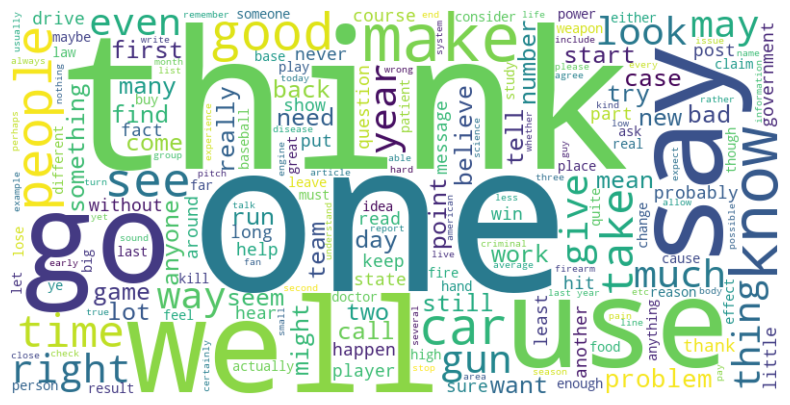

In [257]:
#Create Word Cloud for the desired column of the dataframe data_reduced
#This column is the fully preprocessed version of the original data
text_data = ' '.join(data_reduced['NoStopWords'].fillna('').astype(str).tolist())

import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
from nltk.corpus import stopwords

#Define additional stop words as necessary to remove from the word cloud
stopwords = set(STOPWORDS)
#Custom Stopwords (use as necessary to become more familiar with relevant, high-value data)
stopwords.update(["class"])

#Generate the word cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords = stopwords,
    min_font_size=10
).generate(text_data)

#Display the generated image using matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off") # Hide the axis ticks
plt.savefig ('content/WordCloud.png')
plt.show()

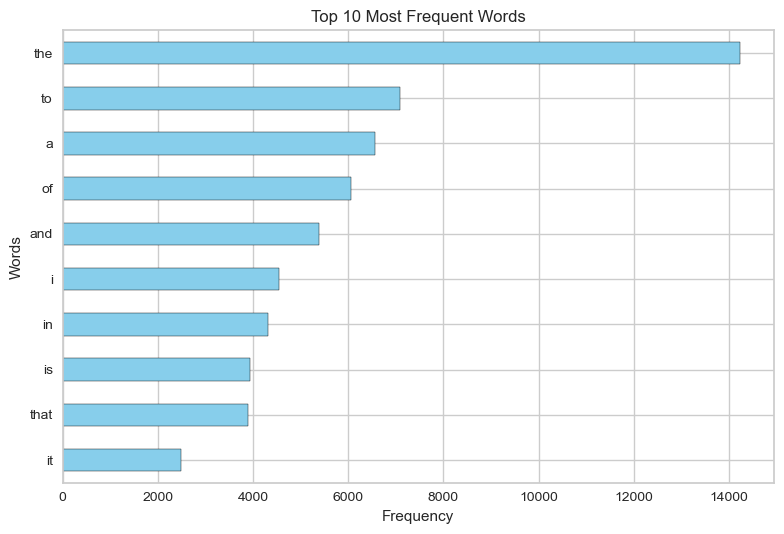

In [258]:
import pandas as pd
import matplotlib.pyplot as plt

#Tokenize words, count frequencies, and grab the top 10 most common words
#Adjust "10" in the code below to accommodate more or fewer top words
word_counts = (
    data_reduced['LowerCase']
    .str.lower()
    .str.split()
    .explode()
    .value_counts()
    .head(10)
)

#Plot a horizontal bar chart (inverted so the highest frequency is at the top)
word_counts.sort_values(ascending=True).plot.barh(color='skyblue', edgecolor='black')

#Customize and display the chart
plt.title('Top 10 Most Frequent Words')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.tight_layout()
plt.savefig ('content/BarChart.png')
plt.show()


# Word Embedding
Convert words in corpus to numerical vectors.  Part 3 embeds the corpus twice: once with Frequency/Counts scoring and once with TF-IDF scoring

In [259]:
#Part 3: Frequency-Counts Word Embeddding

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
from scipy.sparse import csr_matrix

#Embed Documents (document)
#min_df defines the minimum number of times a word occurs in the corpus to be embedded
#max_df defines the maximum (%) frequency a word occurs in the corpus to be embedded
#In the example below, embedding will ignore words that occur in over 80% of the doucments
#And it will ignore words that occur less than twice; these parametrs can be adjusted as needed

#stop_words='english' is NOT used: stopwords were already removed in preprocessing (NLTK list), and
#scikit-learn's built-in list would also delete topic words such as fire, bill and system
#Comment out the word embedding method tha tis not desired:
#Frequency/Counts embedding
count_vect = CountVectorizer(max_df=0.8, min_df=2,ngram_range=(1,1))
#Or
#TF/IDF embedding
#count_vect = TfidfVectorizer(max_df=0.8, min_df=2,ngram_range=(1,1))

doc_term = count_vect.fit_transform(data_reduced.loc[:, 'NoStopWords'])
print ("Abbreviated matrix (includes only non-zero elements) after Embedding")
print ()
print (doc_term)
print ()

#Print entire sparse matrix
#Prints only non-zero elements of matrix
print ("Complete matrix after Embedding")
print()
print(doc_term.toarray())

#Keep the Frequency/Counts embedding so it can be compared to TF-IDF
doc_term_counts = doc_term
print ("Documents x words: ", doc_term_counts.shape)

In [260]:
#Generate and Print embedded/vectorized vector for each word in corpus
#Useful for explanatory/learning purposes only
#Export to a file if desired to view complete, embedded corpus

#Rename original fully preprocessed corpus (before it was embedded/vectorized)
text_corpus = (data_reduced.loc[:, 'NoStopWords'])

#Get feature names (words) for each embedded/vectorized word
# Use get_feature_names_out() for recent sklearn versions
feature_names = count_vect.get_feature_names_out()
print (feature_names)

#Convert the sparse, embedded/vectorized matrix to a dense NumPy array for viewing
# Each row represents a document, and each column represents a frequency/count score
doc_term_dense = doc_term.toarray()

#Display the words and their vector representations
print("Feature Names (Vocabulary):", feature_names)
print()
print("Vectorized Matrix (Documents as rows, words as columns):")
print()
print(doc_term_dense)

#Create a Pandas DataFrame for easier viewing
embedded_dataframe = pd.DataFrame(doc_term_dense, columns=feature_names)
print("\nDataFrame representation of the embedded words and documents:")
print ()
print(embedded_dataframe)

# Visualize Embedded Results
(Optional) Prior to k-means, visulize results using principal component analysis to project the high dimension word embeddings to two dimensions.  Useful for viewing the difference between frequency/counts embedding and TF-IDF embedding.  

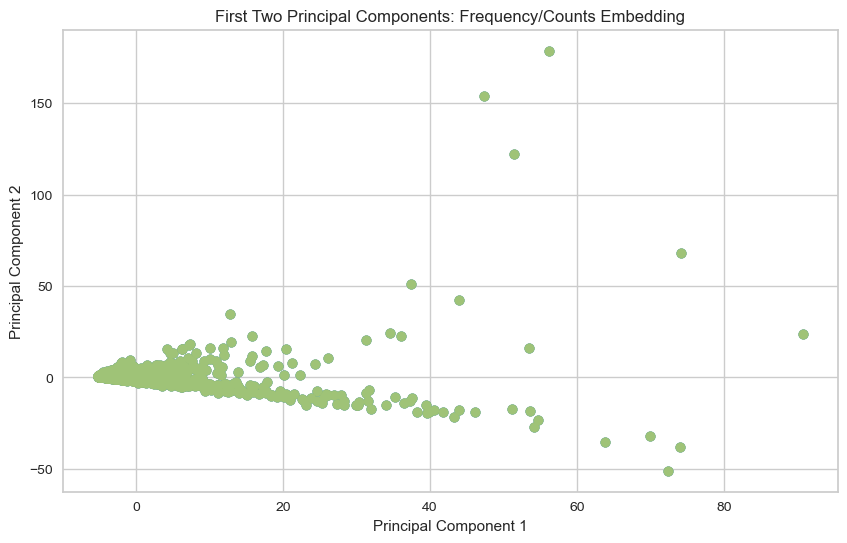

In [261]:
#Reduce Dimensions of Embedded Documents using Principal Component Analysis and Plot the Results
#For visuaizaing how Frequency/Counts embedding/vectorization captured the data corpus

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.datasets import load_iris

#Standardize the features (Crucial: PCA is sensitive to data scale)
scaler = StandardScaler(with_mean=False)
doc_term_scaled = scaler.fit_transform(doc_term_counts)

#Instantiate and fit PCA
#Define number of dimensions (components) that data will be reduced to
number_components = 10   #Part 3 asks for a minimum of ten principal components
pca = PCA(n_components=number_components) # Reduce dimensionality to n_components dimensions
principal_components = pca.fit_transform(doc_term_scaled)

#Find the variance accounted for by number_components cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print("Cumulative variance ratio:", cumulative_variance)
print ("Variance accounted for by", number_components, "principal components (Frequency/Counts): ", cumulative_variance[-1])


#Convert the results back into a clean Pandas DataFrame
pca_cols = [f'PC{i+1}' for i in range(pca.n_components)]
doc_term_pca = pd.DataFrame(data=principal_components, columns=pca_cols, index=data_reduced.index)


# # # Reduce dimensions to two dimensions
# pca = PCA(n_components=4)
# pca_results = pca.fit_transform (doc_term)

# #Print text corpus for easy access
# print (text_corpus)
# print ()

#Create figure
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(principal_components[:, 0], principal_components[:, 1], alpha=0.7)

# Plot the results
plt.scatter(principal_components[:, 0], principal_components[:, 1])

#Label the axes and the plot the first two principal components
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.grid(True)
ax.set_title('First Two Principal Components: Frequency/Counts Embedding')
plt.savefig ('content/PCA_Counts.png')

plt.show()

# TF-IDF Word Embedding
Same corpus, embedded with TF-IDF scoring, then reduced to ten principal components

In [262]:
#Part 3: TF-IDF Word Embeddding

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
from scipy.sparse import csr_matrix

#Embed Documents (document)
#min_df defines the minimum number of times a word occurs in the corpus to be embedded
#max_df defines the maximum (%) frequency a word occurs in the corpus to be embedded
#In the example below, embedding will ignore words that occur in over 80% of the doucments
#And it will ignore words that occur less than twice; these parametrs can be adjusted as needed

#stop_words='english' is NOT used: stopwords were already removed in preprocessing (NLTK list), and
#scikit-learn's built-in list would also delete topic words such as fire, bill and system
#Comment out the word embedding method tha tis not desired:
#Frequency/Counts embedding
#count_vect = CountVectorizer(max_df=0.8, min_df=2,ngram_range=(1,1))
#Or
#TF/IDF embedding
count_vect = TfidfVectorizer(max_df=0.8, min_df=2,ngram_range=(1,1))

doc_term = count_vect.fit_transform(data_reduced.loc[:, 'NoStopWords'])
print ("Abbreviated matrix (includes only non-zero elements) after Embedding")
print ()
print (doc_term)
print ()

#Print entire sparse matrix
#Prints only non-zero elements of matrix
print ("Complete matrix after Embedding")
print()
print(doc_term.toarray())

#Keep the TF-IDF embedding so it can be compared to Frequency/Counts
doc_term_tfidf = doc_term
print ("Documents x words: ", doc_term_tfidf.shape)

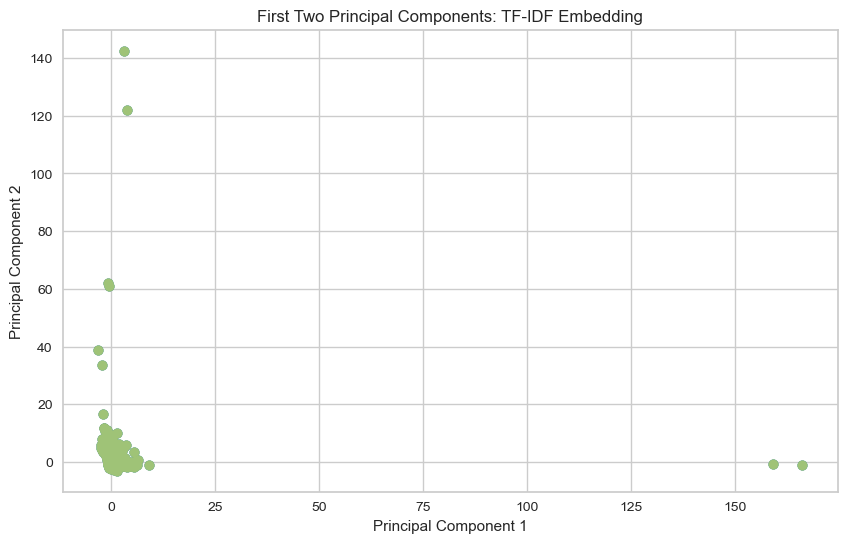

In [263]:
#Reduce Dimensions of Embedded Documents using Principal Component Analysis and Plot the Results
#For visuaizaing how TF-IDF embedding/vectorization captured the data corpus

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.datasets import load_iris

#Standardize the features (Crucial: PCA is sensitive to data scale)
scaler = StandardScaler(with_mean=False)
doc_term_scaled = scaler.fit_transform(doc_term_tfidf)

#Instantiate and fit PCA
#Define number of dimensions (components) that data will be reduced to
number_components = 10   #Part 3 asks for a minimum of ten principal components
pca = PCA(n_components=number_components) # Reduce dimensionality to n_components dimensions
principal_components = pca.fit_transform(doc_term_scaled)

#Find the variance accounted for by number_components cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print("Cumulative variance ratio:", cumulative_variance)
print ("Variance accounted for by", number_components, "principal components (TF-IDF): ", cumulative_variance[-1])


#Convert the results back into a clean Pandas DataFrame
pca_cols = [f'PC{i+1}' for i in range(pca.n_components)]
doc_term_pca = pd.DataFrame(data=principal_components, columns=pca_cols, index=data_reduced.index)


# # # Reduce dimensions to two dimensions
# pca = PCA(n_components=4)
# pca_results = pca.fit_transform (doc_term)

# #Print text corpus for easy access
# print (text_corpus)
# print ()

#Create figure
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(principal_components[:, 0], principal_components[:, 1], alpha=0.7)

# Plot the results
plt.scatter(principal_components[:, 0], principal_components[:, 1])

#Label the axes and the plot the first two principal components
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.grid(True)
ax.set_title('First Two Principal Components: TF-IDF Embedding')
plt.savefig ('content/PCA_TFIDF.png')

plt.show()

# Parameter Tuning: Selecting the Word Embedding
Compare Frequency/Counts and TF-IDF embeddings with different min_df and max_df values, and check random_state. Each combination is reduced to 10 principal components and clustered with k-Means (4 clusters); the known topics are used only to score how well the clusters match them.

In [264]:
#Parameter Tuning: compare word embeddings (Counts vs TF-IDF) and min_df / max_df
#For each combination: embed, standardize, reduce to 10 principal components, run k-Means with 4 clusters,
#and score how well the clusters match the 4 known topics (accuracy and macro F1-score)
#min_df ignores words that occur in fewer than min_df documents
#max_df ignores words that occur in more than max_df (%) of the documents
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score
from scipy.optimize import linear_sum_assignment
import pandas as pd
import numpy as np

#Define function that matches each cluster to one topic
#Each cluster is matched to a different topic, so that as many posts as possible are placed in the right topic
def match_clusters_to_topics(cluster_labels, known_topics):
    """Returns a dictionary {cluster number: topic name}."""
    table = pd.crosstab(cluster_labels, known_topics)
    rows, cols = linear_sum_assignment(-table.values)
    return {table.index[r]: table.columns[c] for r, c in zip(rows, cols)}

#The known topic of every post (used only for scoring)
known_topics = data_reduced['target_name'].values

#Modify (add, remove) the values to test as needed/desired
tuning_results = []
for embedding in ['Counts', 'TF-IDF']:
    for min_df in [2, 5, 10, 20, 50, 100]:
        for max_df in [0.8, 0.5, 0.3, 0.1]:
            if embedding == 'Counts':
                vectorizer = CountVectorizer(max_df=max_df, min_df=min_df, ngram_range=(1,1))
            else:
                vectorizer = TfidfVectorizer(max_df=max_df, min_df=min_df, ngram_range=(1,1))
            doc_term_tuning = vectorizer.fit_transform(data_reduced.loc[:, 'NoStopWords'])

            #Standardize, reduce to 10 principal components and perform k-Means with 4 clusters
            doc_term_scaled = StandardScaler(with_mean=False).fit_transform(doc_term_tuning)
            pca = PCA(n_components=10)
            pca_results = pca.fit_transform(doc_term_scaled)
            labels = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(pca_results)

            #Score the clusters against the known topics
            mapping = match_clusters_to_topics(labels, known_topics)
            predicted_topics = [mapping[label] for label in labels]
            tuning_results.append({'Embedding': embedding, 'min_df': min_df, 'max_df': max_df,
                                   'Words': doc_term_tuning.shape[1],
                                   'Variance (10 PCs)': round(pca.explained_variance_ratio_.sum(), 3),
                                   'Accuracy': round(accuracy_score(known_topics, predicted_topics), 3),
                                   'Macro F1-score': round(f1_score(known_topics, predicted_topics, average='macro'), 3),
                                   'Cluster Sizes': sorted(np.bincount(labels).tolist(), reverse=True)})

#Print the results, best macro F1-score first, and export them to MS Excel
tuning_results = pd.DataFrame(tuning_results).sort_values('Macro F1-score', ascending=False)
print (tuning_results.to_string(index=False))
tuning_results.to_excel('content/ParameterTuning.xlsx', index=False)

In [265]:
#Check random_state for the selected settings (TF-IDF, min_df = 20, max_df = 0.8)
#random_state sets where k-Means starts; the same random_state always gives the same result (reproducible)
#Trying different random_state values shows whether the result depends on the starting point
vectorizer = TfidfVectorizer(max_df=0.8, min_df=20, ngram_range=(1,1))
doc_term_scaled = StandardScaler(with_mean=False).fit_transform(vectorizer.fit_transform(data_reduced.loc[:, 'NoStopWords']))
pca_results = PCA(n_components=10).fit_transform(doc_term_scaled)

for random_state in range(10):
    labels = KMeans(n_clusters=4, random_state=random_state, n_init=10).fit_predict(pca_results)
    mapping = match_clusters_to_topics(labels, known_topics)
    predicted_topics = [mapping[label] for label in labels]
    print ("random_state =", random_state, "  accuracy =", round(accuracy_score(known_topics, predicted_topics), 3),
           "  macro F1-score =", round(f1_score(known_topics, predicted_topics, average='macro'), 3))

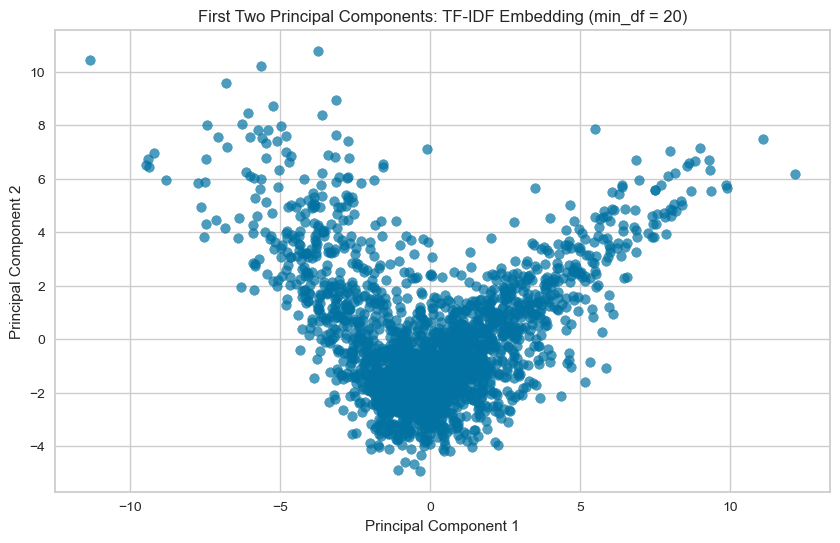

In [266]:
#Selected Word Embedding (from Parameter Tuning): TF-IDF with min_df = 20 and max_df = 0.8
#Requiring a word to occur in at least 20 posts removes rare words; standardizing gave rare words a very large
#weight, which pushed a few posts far away from the rest and hid the topics from k-Means
from sklearn.feature_extraction.text import TfidfVectorizer
selected_min_df = 20
selected_max_df = 0.8
count_vect = TfidfVectorizer(max_df=selected_max_df, min_df=selected_min_df, ngram_range=(1,1))
doc_term_selected = count_vect.fit_transform(data_reduced.loc[:, 'NoStopWords'])
print ("Documents x words: ", doc_term_selected.shape)

#Reduce Dimensions using Principal Component Analysis and Plot the first two Principal Components
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np

#Standardize the features (Crucial: PCA is sensitive to data scale)
scaler = StandardScaler(with_mean=False)
doc_term_scaled = scaler.fit_transform(doc_term_selected)

#Instantiate and fit PCA
number_components = 10
pca = PCA(n_components=number_components) # Reduce dimensionality to n_components dimensions
principal_components = pca.fit_transform(doc_term_scaled)

#Find the variance accounted for by number_components
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print("Cumulative variance ratio:", cumulative_variance)
print ("Variance accounted for by", number_components, "principal components (selected TF-IDF): ", cumulative_variance[-1])

#Create figure and plot the first two principal components
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(principal_components[:, 0], principal_components[:, 1], alpha=0.7)
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.grid(True)
ax.set_title('First Two Principal Components: TF-IDF Embedding (min_df = 20)')
plt.savefig ('content/PCA_TFIDF_Selected.png')
plt.show()

# Find Optimal Number of Clusters/Topics using k-Means

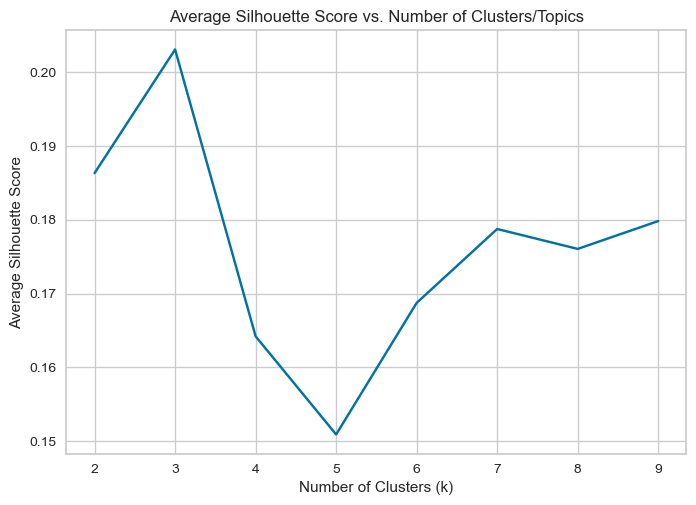

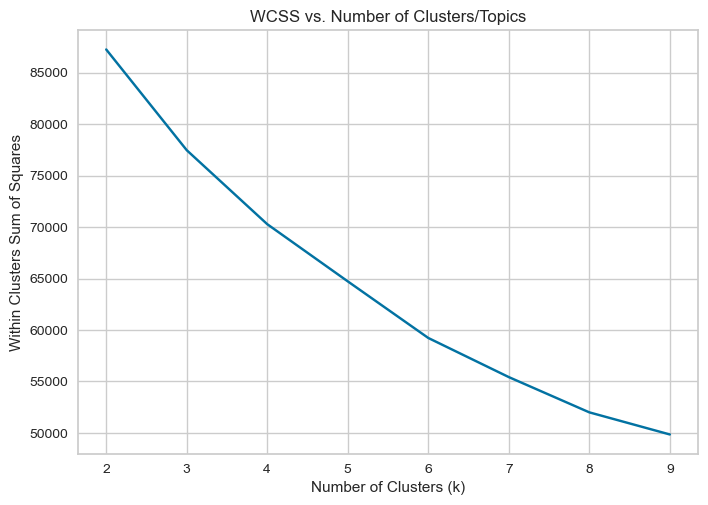

In [267]:
#Option #1:  Optimize number of Topics by
#Performing kMeans on data whose dimensions have been first reduced using PCA
#Part 4 uses the word embedding selected by Parameter Tuning (TF-IDF, min_df = 20, max_df = 0.8)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from yellowbrick.cluster import SilhouetteVisualizer
from yellowbrick.datasets import load_nfl
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris

#Standardize the features (Crucial: PCA is sensitive to data scale)
scaler = StandardScaler(with_mean=False)
doc_term_scaled = scaler.fit_transform(doc_term_selected)

#Instantiate and fit PCA
#Define number of dimensions (components) that data will be reduced to
number_components = 10
pca = PCA(n_components=number_components) # Reduce dimensionality to n_components dimensions
pca_results = pca.fit_transform(doc_term_scaled)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print("Cumulative variance ratio:", cumulative_variance)

#Find optimal number of clusters using WCSS, silhouette scores, or a combination thereof
#Find optimal number of clusters (topics that describe the data) using silhouette scores
#The highest silhouette score indicates the optimal number of clusters
silhouette_scores = []
k_range = range(2, 10) #Evaluate 2, 3, 4, 5, 6, 7, 8, 9 clusters
for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init for robust initialization
        kmeans.fit(pca_results)
        score = silhouette_score(pca_results, kmeans.labels_)
        print ("For ", k, "clusters, the silhouette score is ", score)
        silhouette_scores.append(score)

plt.plot(k_range, silhouette_scores)
plt.title('Average Silhouette Score vs. Number of Clusters/Topics')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.savefig ('content/Silhouette_vs_k.png')
plt.show()

#Find optimal number of clusters using within cluster sum of squares (and elbow method)
#The smallest within cluster sum of squares indicates the optimal number of topics
wcss = []
# Iterate through a range of possible cluster numbers (e.g., 1 to 10)
for i in range(2, 10):
        kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
        kmeans.fit(pca_results)
        wcss.append(kmeans.inertia_) # Inertia is the WCSS
        print ("For ", i, "clusters, the WCSS is ", kmeans.inertia_)

plt.plot(range(2, 10), wcss)
plt.title('WCSS vs. Number of Clusters/Topics')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within Clusters Sum of Squares')
plt.savefig ('content/WCSS_vs_k.png')
plt.show()




# Part 5: Perform k-Means Clustering (4 Clusters) and Evaluate Performance

In [268]:
#Create an empty dataframe for storing results
kMeans_results = pd.DataFrame()

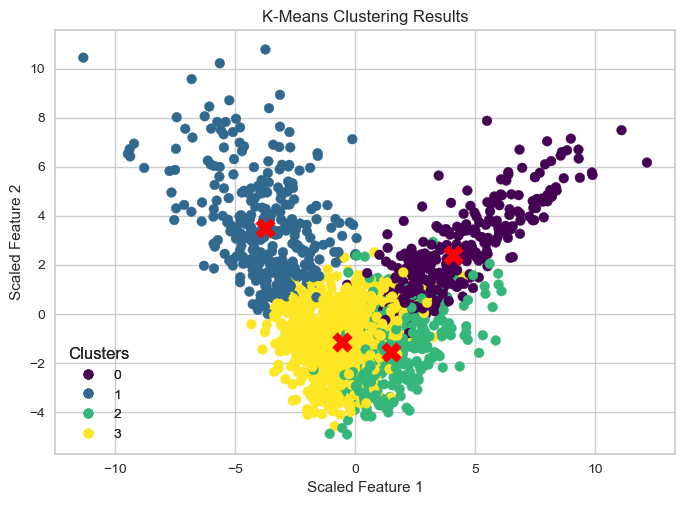

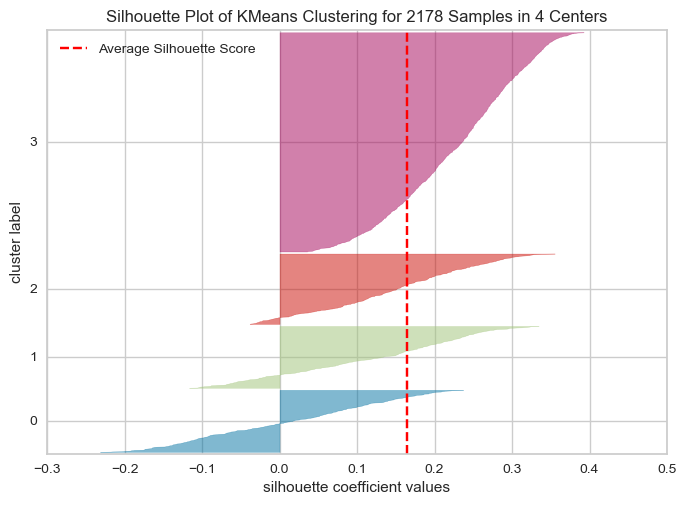

In [269]:
#Option #1:  Perform kMeans on data whose dimensions have been first reduced using PCA
#Part 5 uses the selected word embedding (TF-IDF, min_df = 20) and the same 10 principal components as Part 4
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from yellowbrick.cluster import SilhouetteVisualizer
from yellowbrick.datasets import load_nfl
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#Standardize the features (Crucial: PCA is sensitive to data scale)
scaler = StandardScaler(with_mean=False)
doc_term_scaled = scaler.fit_transform(doc_term_selected)
#Instantiate and fit PCA
pca = PCA(n_components=10) # Reduce dimensionality to n_components dimensions
principal_components = pca.fit_transform(doc_term_scaled)

#Perform k-Means Analysis
#setting random_state forces kMeans to start with the same random centroid locations and thereby deliver consistent results
#n_init is the number of iterations kMeans makes to determine the best cluster locations
#n_clusters is the number of clusters that kmeans will create
optimal_number_clusters = 4   #Part 5: four clusters, one for each known topic
kmeans_model = KMeans(n_clusters=optimal_number_clusters, random_state=42, n_init=10)
kmeans_model.fit(principal_components)
cluster_labels = kmeans_model.labels_
cluster_centers = kmeans_model.cluster_centers_

#Plot the results of k-Means Analysis
fig, ax = plt.subplots()
scatter = ax.scatter(principal_components[:, 0], principal_components[:, 1], c=cluster_labels, cmap='viridis')
legend1 = ax.legend(*scatter.legend_elements(), title="Clusters")
ax.add_artist(legend1)
plt.scatter(cluster_centers[:, 0], cluster_centers[:, 1], s=200, marker='X', c='red', label='Centroids')
plt.title('K-Means Clustering Results')
plt.xlabel('Scaled Feature 1')
plt.ylabel('Scaled Feature 2')
plt.savefig ('content/kMeans_4_Clusters.png')
plt.show()
#Note: Cluster centroids are shown as big red X

#Visualize the Silhouette Scores for the chosen number of clusters
#This provides additional insight into whether the chosen number of clusters is truly optimal
#Instantiate the clustering model and visualizer
#Note that the "cluster label" starts at 0 (e.g., 5 clusters would be labelled 0, 1, 2, 3, 4)
#X must be the same data k-Means was fit on (principal_components); pca_results was left over from another cell
X = principal_components
visualizer = SilhouetteVisualizer(kmeans_model, colors='yellowbrick')
visualizer.fit(X)        # Fit the data to the visualizer
visualizer.show()        # Finalize and render the figure

#Save assigned clusters and first two principal components to dataframe
kMeans_results['Assigned Cluster for Option 1'] = cluster_labels
kMeans_results['Principal Component 1 for Option 1'] = principal_components[:, 0]
kMeans_results['Principal Component 2 for Option 1'] = principal_components[:, 1]
print (kMeans_results)

In [270]:
#Part 5: Determine which Cluster corresponds to which Topic
#Table of how many posts from each known topic were placed in each cluster
cluster_topic_table = pd.crosstab(kMeans_results['Assigned Cluster for Option 1'].values, data_reduced['target_name'].values,
                                  rownames=['Cluster'], colnames=['Known Topic'])
print (cluster_topic_table)
print () #print a blank line as a spacer

#Match each cluster to one topic (each topic is used once), using match_clusters_to_topics from Parameter Tuning
cluster_to_topic = match_clusters_to_topics(kMeans_results['Assigned Cluster for Option 1'].values, data_reduced['target_name'].values)
for cluster, topic in sorted(cluster_to_topic.items()):
    print ("Cluster", cluster, "corresponds to", topic)

#Save the known topic and the topic assigned by k-Means for every post
kMeans_results['Known Topic'] = data_reduced['target_name'].values
kMeans_results['Assigned Topic'] = kMeans_results['Assigned Cluster for Option 1'].map(cluster_to_topic)

#Export the cluster/topic table to MS Excel
cluster_topic_table.to_excel('content/Part5_Cluster_Topic_Table.xlsx')

In [271]:
#Part 5: Calculate Accuracy and F1-score per Topic
#Accuracy per topic = share of the topic's posts that were placed in the cluster matched to that topic
#Precision per topic = share of the posts in the matched cluster that really belong to the topic
#F1-score per topic = balance of precision and accuracy (recall); macro F1-score = average F1-score of the 4 topics
from sklearn.metrics import accuracy_score, precision_score, f1_score

known = kMeans_results['Known Topic']
assigned = kMeans_results['Assigned Topic']

part5_results = []
for topic in sorted(known.unique()):
    in_topic = known == topic
    correct = (in_topic & (assigned == topic)).sum()
    part5_results.append({'Topic': topic,
                          'Posts': in_topic.sum(),
                          'Correctly Clustered': correct,
                          'Accuracy': round(correct / in_topic.sum(), 3),
                          'Precision': round(precision_score(known, assigned, labels=[topic], average='macro'), 3),
                          'F1-score': round(f1_score(known, assigned, labels=[topic], average='macro'), 3)})

#Add a row for all 4 topics: overall accuracy, macro precision and macro F1-score
part5_results.append({'Topic': 'All topics (overall accuracy, macro average)',
                      'Posts': len(known),
                      'Correctly Clustered': (known == assigned).sum(),
                      'Accuracy': round(accuracy_score(known, assigned), 3),
                      'Precision': round(precision_score(known, assigned, average='macro'), 3),
                      'F1-score': round(f1_score(known, assigned, average='macro'), 3)})

#Print the results table and export it to MS Excel
part5_results = pd.DataFrame(part5_results)
print (part5_results.to_string(index=False))
part5_results.to_excel('content/Part5_Results.xlsx', index=False)

In [272]:
#Print Clusters to Output File
#File will be located in the filepath defined previously (or alternatively a new filepath can be designated here)
#In this notebook, the exported file is placed in the "content" folder in the CoLab drive
#and needs to be downloaded before quitting the CoLab session

import numpy as np
import pandas as pd

#Create Output Dataframe consisting of Original Response and the Cluster assigned to each Response

#Reset indices for original responses in data_reduced
#This ensures that any blank responses that were removed
#in a previous cell do not disrupt the alignment of the cluster data
#with the original data
temp1_df = data_reduced.reset_index(drop=True)
temp2_df = temp1_df['OriginalResponse']
#temp3_df = pd.DataFrame(cluster_labels, columns=['Assigned Cluster'])
output_df = pd.concat([temp2_df, kMeans_results], axis=1)

##xport Output Dataframe to MS Excel
file_name = 'content/NewsGroupData_kMeans_Results.xlsx'
output_df.to_excel(file_name, index=False)